# Matrix Chain Multiplication using Dynamic Programming

For the fixed matrix chain A1 A2 ... An, determine a parenthesization requiring the minimum number of scalar multiplications.

The order of the matrices is not changed. Only the placement of parentheses is changed.


## 1. Mathematical concept

Let the dimension vector be

p = [p0, p1, ..., pn].

Then matrix Ai has dimensions

p(i-1) x pi.

Multiplying an a x b matrix by a b x c matrix requires

a*b*c

scalar multiplications.

Let m[i][j] denote the minimum cost of computing Ai ... Aj.

For a single matrix,

m[i][i] = 0.

If Ai ... Aj is split after Ak, where i <= k < j, then the cost is

m[i][k] + m[k+1][j] + p[i-1]*p[k]*p[j].

Therefore,

m[i][j] = minimum over i <= k < j of

m[i][k] + m[k+1][j] + p[i-1]*p[k]*p[j].

The split position attaining the minimum is stored in s[i][j].


## 2. Bottom-up minimum-cost algorithm

1. Set m[i][i] = 0 for every i.
2. Consider subchains of length 2, 3, ..., n.
3. For each subchain Ai ... Aj, test every split k from i to j-1.
4. Compute the cost corresponding to each split.
5. Store the smallest cost in m[i][j].
6. Store the attaining split in s[i][j].
7. Use s to reconstruct the optimal parenthesization.

Time complexity: O(n^3)

Space complexity: O(n^2)


In [2]:
def matrix_chain_minimum(p):
    n = len(p) - 1
    m = [[0] * (n + 1) for _ in range(n + 1)]
    s = [[None] * (n + 1) for _ in range(n + 1)]

    for length in range(2, n + 1):
        for i in range(1, n - length + 2):
            j = i + length - 1
            m[i][j] = float("inf")

            for k in range(i, j):
                cost = (
                    m[i][k]
                    + m[k + 1][j]
                    + p[i - 1] * p[k] * p[j]
                )

                if cost < m[i][j]:
                    m[i][j] = cost
                    s[i][j] = k

    return m, s


def parenthesization(s, i, j):
    if i == j:
        return f"A{i}"

    k = s[i][j]
    left = parenthesization(s, i, k)
    right = parenthesization(s, k + 1, j)
    return f"({left} x {right})"


# Illustration
p = [40, 20, 30, 10, 30]
m, s = matrix_chain_minimum(p)
n = len(p) - 1

print("Minimum cost:", m[1][n])
print("Optimal parenthesization:", parenthesization(s, 1, n))


Minimum cost: 26000
Optimal parenthesization: ((A1 x (A2 x A3)) x A4)


# Exercise 1: Maximum-cost parenthesization

For p = [100, 2, 100, 2], modify the minimum-cost algorithm to find the maximum-cost parenthesization. Compare the minimum and maximum costs using a bar graph, and calculate their ratio.


--- Exercise 1 Results ---
Minimum cost: 26000
Optimal (Min) parenthesization: ((A1 x (A2 x A3)) x A4)
Maximum cost: 69000
Worst (Max) parenthesization: ((A1 x A2) x (A3 x A4))
Ratio (Max / Min): 2.65


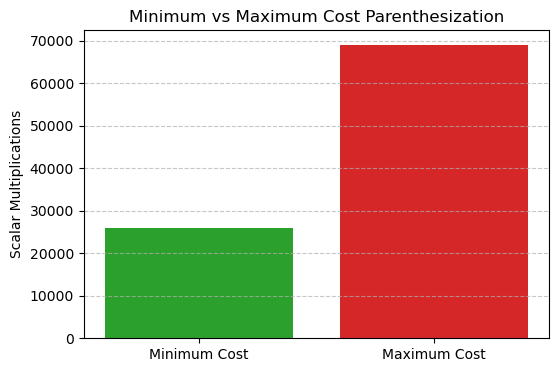

In [7]:
import matplotlib.pyplot as plt
p = [40, 20, 30, 10, 30]

n = len(p) - 1

def matrix_chain_maximum(p):
    n = len(p) - 1
    m = [[0] * (n + 1) for _ in range(n + 1)]
    s = [[None] * (n + 1) for _ in range(n + 1)]

    for length in range(2, n + 1):
        for i in range(1, n - length + 2):
            j = i + length - 1
            m[i][j] = float("-inf")  # Track maximum instead of minimum

            for k in range(i, j):
                cost = (
                    m[i][k]
                    + m[k + 1][j]
                    + p[i - 1] * p[k] * p[j]
                )

                if cost > m[i][j]:  # Select larger cost
                    m[i][j] = cost
                    s[i][j] = k

    return m, s

n = len(p) - 1

# Calculate Minimum Cost using the provided notebook function
m_min, s_min = matrix_chain_minimum(p)
min_cost = m_min[1][n]

# Calculate Maximum Cost
m_max, s_max = matrix_chain_maximum(p)
max_cost = m_max[1][n]

# Calculate ratio
ratio = max_cost / min_cost

# Print Results
print("--- Exercise 1 Results ---")
print("Minimum cost:", min_cost)
print("Optimal (Min) parenthesization:", parenthesization(s_min, 1, n))
print("Maximum cost:", max_cost)
print("Worst (Max) parenthesization:", parenthesization(s_max, 1, n))
print(f"Ratio (Max / Min): {ratio:.2f}")

# Plot Bar Graph Comparison
plt.figure(figsize=(6, 4))
plt.bar(['Minimum Cost', 'Maximum Cost'], [min_cost, max_cost], color=['#2ca02c', '#d62728'])
plt.ylabel('Scalar Multiplications')
plt.title('Minimum vs Maximum Cost Parenthesization')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Exercise 2: Matrix-chain

Let A1, A2, ..., An have dimensions

2 x 3, 3 x 4, 4 x 5, ..., (n+1) x (n+2).

For n = 3, n = 4, n = 5 find the minimum-cost parenthesization and its cost.  From the computed values, conjecture a format for optimal parenthesization.


In [11]:
# Exercise 2 solution workspace
import matplotlib.pyplot as plt

# For a given n, the dimension vector is [2, 3, ..., n+2].
results = []
for n in [3, 4, 5]:
    p = list(range(2, n + 3))
    m, s = matrix_chain_minimum(p)
    cost = m[1][n]
    expr = parenthesization(s, 1, n)
    results.append((n, cost, expr))
    print(f"n = {n}: Minimum Cost = {cost:<5} | Optimal Parenthesization = {expr}")

n = 3: Minimum Cost = 64    | Optimal Parenthesization = ((A1 x A2) x A3)
n = 4: Minimum Cost = 124   | Optimal Parenthesization = (((A1 x A2) x A3) x A4)
n = 5: Minimum Cost = 208   | Optimal Parenthesization = ((((A1 x A2) x A3) x A4) x A5)
